In [10]:
import sys
from pathlib import Path

ROOT_DIR = Path(r"D:\shrey\Documents\ML- PROJECT")
sys.path.insert(0, str(ROOT_DIR))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import config as cfg

sns.set_theme(style="whitegrid")

cfg.VISUALS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(cfg.PROCESSED_DIR / "placement_clean.csv")

# CSV turns True/False + blanks into mixed objects, so restore proper nullable booleans
for col in ["eligible", "oa_cleared", "selected"]:
    df[col] = df[col].map({True: True, False: False, "True": True, "False": False}).astype("boolean")

# Subsets: only rows that actually reached each stage
students    = df.drop_duplicates("student_id")                     # one row per student
eligible_df = df[df["eligible"] == True]                           # took the OA
oa_cleared  = eligible_df[eligible_df["oa_cleared"].notna()]       # same rows, with the OA result
interviewed = df[df["oa_cleared"] == True]                         # reached interviews

SECTIONS = list(cfg.OA_SECTIONS)
ACAD = ["tenth_pct", "twelfth_pct", "jee_percentile", "cgpa"]

print("students:", len(students), "| eligible apps:", len(eligible_df), "| interviewed:", len(interviewed))

students: 3000 | eligible apps: 2990 | interviewed: 960


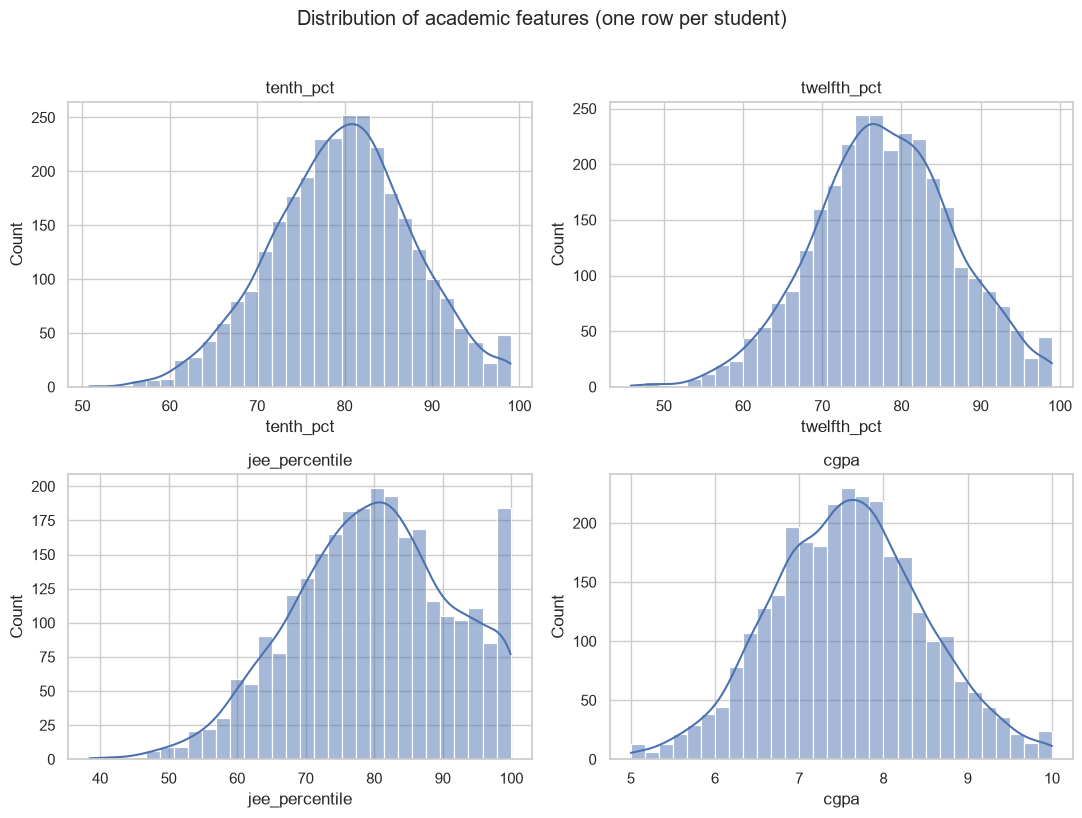

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), ACAD):
    sns.histplot(students[col].dropna(), bins=30, kde=True, ax=ax)
    ax.set_title(col)
fig.suptitle("Distribution of academic features (one row per student)", y=1.02)
plt.tight_layout()
plt.savefig(cfg.VISUALS_DIR / "01_academic_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

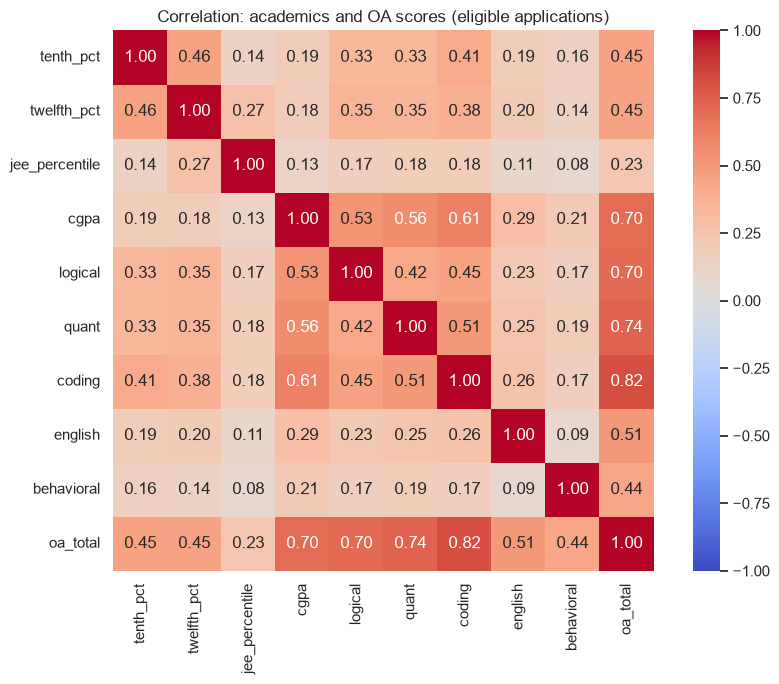

In [12]:
corr = eligible_df[ACAD + SECTIONS + ["oa_total"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation: academics and OA scores (eligible applications)")
plt.tight_layout()
plt.savefig(cfg.VISUALS_DIR / "02_corr_heatmap.png", dpi=150)
plt.show()

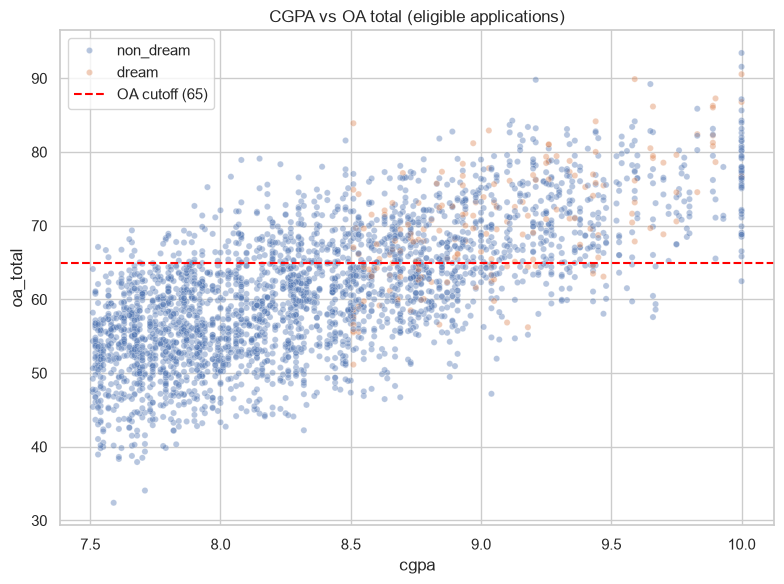

In [13]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=eligible_df, x="cgpa", y="oa_total", hue="company_category",
                alpha=0.4, s=20)
plt.axhline(cfg.OA_CUTOFF_TOTAL, color="red", ls="--", label=f"OA cutoff ({cfg.OA_CUTOFF_TOTAL})")
plt.legend()
plt.title("CGPA vs OA total (eligible applications)")
plt.tight_layout()
plt.savefig(cfg.VISUALS_DIR / "03_cgpa_vs_oa.png", dpi=150)
plt.show()

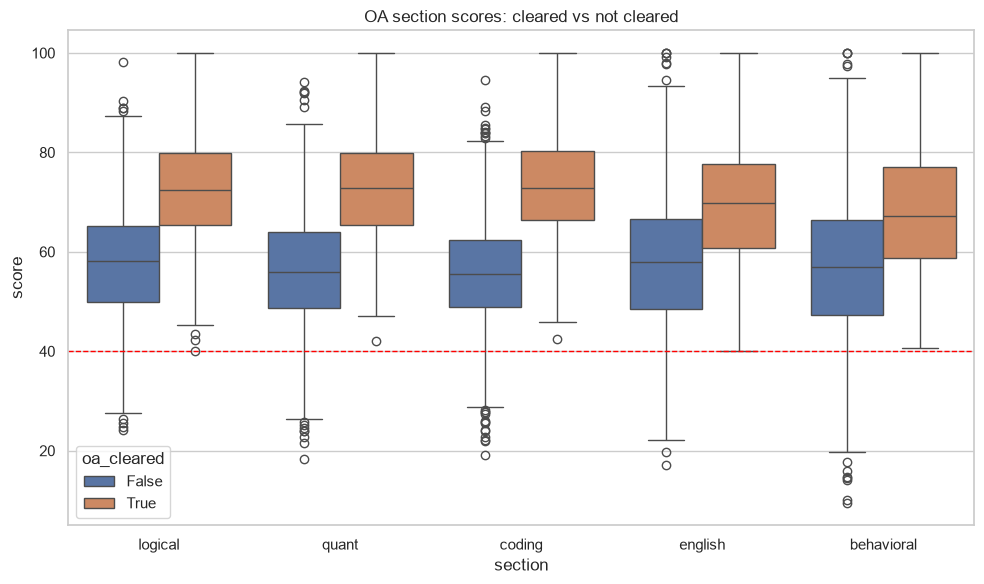

In [14]:
long = oa_cleared.melt(id_vars="oa_cleared", value_vars=SECTIONS,
                       var_name="section", value_name="score")
long["oa_cleared"] = long["oa_cleared"].astype(bool)

plt.figure(figsize=(10, 6))
sns.boxplot(data=long, x="section", y="score", hue="oa_cleared")
plt.axhline(cfg.OA_MIN_PER_SECTION, color="red", ls="--", lw=1)
plt.title("OA section scores: cleared vs not cleared")
plt.tight_layout()
plt.savefig(cfg.VISUALS_DIR / "04_oa_sections_boxplot.png", dpi=150)
plt.show()

                  applications  eligible  oa_cleared  interviewed  selected
company_category                                                           
dream                     5038       171         120          120        32
non_dream                 9962      2819         840          840        64


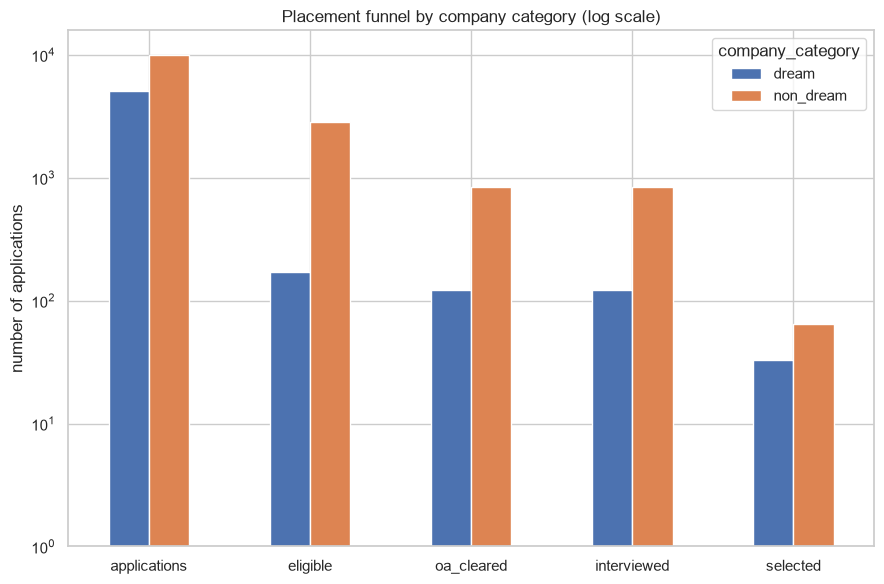

In [15]:
funnel = pd.DataFrame({
    "applications": df.groupby("company_category").size(),
    "eligible":     eligible_df.groupby("company_category").size(),
    "oa_cleared":   (df[df["oa_cleared"] == True]).groupby("company_category").size(),
    "selected":     (df[df["selected"] == True]).groupby("company_category").size(),
})
funnel.insert(3, "interviewed", funnel["oa_cleared"])   # everyone who cleared the OA is interviewed
print(funnel)

funnel.T.plot(kind="bar", figsize=(9, 6), log=True)
plt.title("Placement funnel by company category (log scale)")
plt.ylabel("number of applications")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(cfg.VISUALS_DIR / "05_funnel.png", dpi=150)
plt.show()

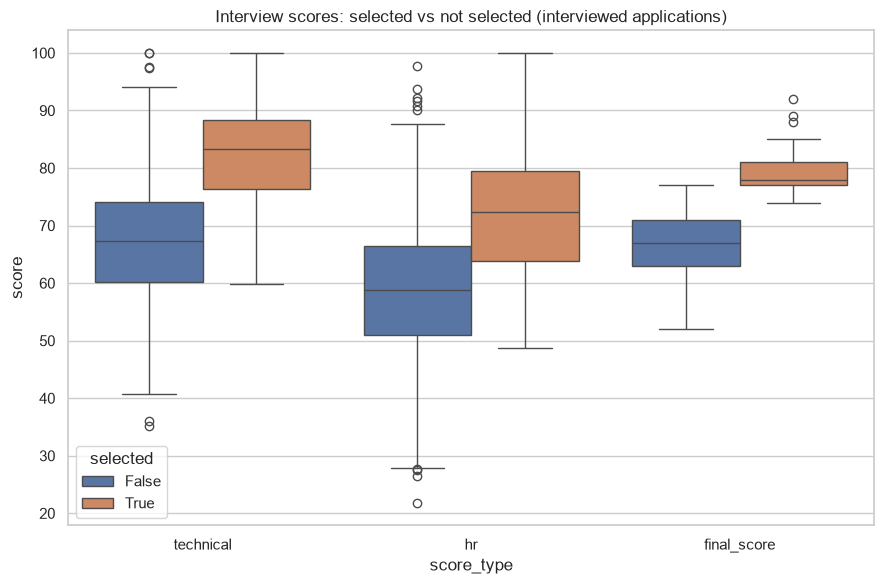

In [16]:
iv_long = interviewed.melt(id_vars="selected", value_vars=["technical", "hr", "final_score"],
                           var_name="score_type", value_name="score")
iv_long["selected"] = iv_long["selected"].astype(bool)

plt.figure(figsize=(9, 6))
sns.boxplot(data=iv_long, x="score_type", y="score", hue="selected")
plt.title("Interview scores: selected vs not selected (interviewed applications)")
plt.tight_layout()
plt.savefig(cfg.VISUALS_DIR / "06_interview_scores.png", dpi=150)
plt.show()